# 02 - Model comparison, selection and evaluation

The eligibility model predicts **Approved / Rejected** from the prepared data. It is one input to the
decision, not the decision itself: the lender's written policy is applied first by a deterministic rules
engine, and the model's approval probability is then compared with a threshold **written in the policy**
(clause NW-3.7 / SB-C7). The model can decline an application that passes the rules; it can never approve
one the rules reject.

**What a mistake costs**
* *False approval* (approving someone who should be declined): credit loss, collections, regulatory
  exposure. Expensive for the lender.
* *False rejection* (declining someone who should be approved): lost interest margin and a frustrated
  customer, who can still ask for manual review.

We assume a false approval costs **5x** a false rejection and choose the model and threshold that minimise
expected cost per application. ROC AUC (ranking quality), PR AUC and the Brier score (calibration) are
reported alongside.

In [1]:
import sys, json, hashlib
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "backend"))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette=["#2b3ab0", "#f6607f", "#36c98b", "#ff9a3c", "#a46cf0"])
pd.set_option("display.width", 140, "display.max_columns", 30)
%matplotlib inline

In [2]:
from app.ml import pipeline as P
from app.ml.features import FEATURES
df = P.clean(pd.read_csv(ROOT / "data/raw/loan_applications.csv"))
x_train, x_test, y_train, y_test = P.split(df)
print("train", x_train.shape, "test", x_test.shape, "approval rate", round(y_train.mean(), 3))

train (9600, 12) test (2400, 12) approval rate 0.533


## 1. Candidate models

Four approaches of increasing flexibility, each tuned with a small grid and 5-fold stratified CV on the
training split only: logistic regression (linear, interpretable baseline), a decision tree (readable rules),
a random forest and histogram gradient boosting (non-linear interactions, robust to missing values).

In [3]:
table, fitted = P.compare(x_train, y_train)
table.round(4)

,model,best_params,cv_roc_auc,cv_pr_auc,cv_brier,cv_false_approval_rate,cv_false_rejection_rate,cv_expected_cost_per_application,cv_threshold
0,gradient_boosting,"{""clf__learning_rate"": 0.1, ""clf__max_depth"": 3}",0.9626,0.9600,0.0607,0.0560,0.2016,0.2382,0.83
1,random_forest,"{""clf__max_depth"": 14, ""clf__min_samples_leaf""...",0.9615,0.9578,0.0617,0.0600,0.1916,0.2423,0.80
2,decision_tree,"{""clf__max_depth"": 8, ""clf__min_samples_leaf"":...",0.9458,0.9292,0.0662,0.0973,0.1287,0.2957,0.80
3,logistic_regression,"{""clf__C"": 10.0}",0.8614,0.8421,0.1478,0.0652,0.5996,0.4719,0.82


In [4]:
card = json.loads((ROOT / "models/model_card.json").read_text())
chosen = card["algorithm"]
print("selected:", chosen, "| policy threshold:", card["decision_threshold"])
assert table.iloc[0]["model"] == chosen

selected: gradient_boosting | policy threshold: 0.83


**Why this model.** The ranking is by cross-validated expected cost (then ROC AUC). The tree
ensembles clearly beat logistic regression because eligibility depends on thresholds and interactions
(for example, income only matters once the credit score clears a bar). Gradient boosting is selected:
it has the lowest expected cost, handles missing values natively, and is small and fast to score.
The decision tree is kept as a readable reference but is less accurate.

## 2. Threshold chosen by cost

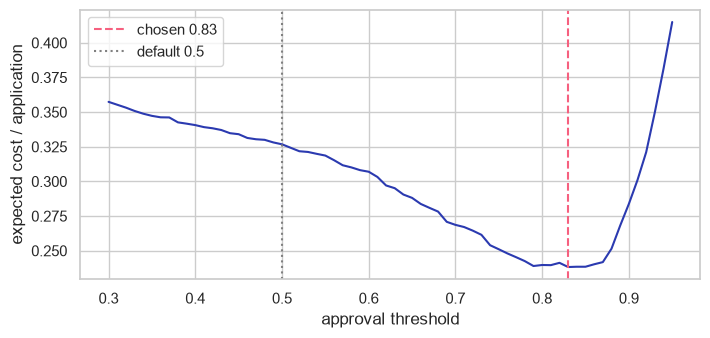

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
model = fitted[chosen]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=P.SEED)
oof = cross_val_predict(model, x_train, y_train, cv=cv, method="predict_proba")[:, 1]
grid = np.round(np.arange(0.30, 0.951, 0.01), 2)
costs = [P.expected_cost(y_train, oof, t) for t in grid]
plt.figure(figsize=(8, 3.5)); plt.plot(grid, costs)
plt.axvline(card["decision_threshold"], color="#f6607f", ls="--", label=f"chosen {card['decision_threshold']}")
plt.axvline(0.5, color="grey", ls=":", label="default 0.5")
plt.xlabel("approval threshold"); plt.ylabel("expected cost / application"); plt.legend(); plt.show()

## 3. Held-out test evaluation of the saved model

In [6]:
from app.ml.model import EligibilityModel
saved = EligibilityModel.load(ROOT / "models")
assert saved is not None, "model hash does not match its card"
proba = saved._pipeline.predict_proba(x_test[FEATURES])[:, 1]
test = P.metrics(y_test, proba, card["decision_threshold"])
pd.Series(test).to_frame("test").T

,roc_auc,pr_auc,precision_approved,recall_approved,f1,brier,false_approval_rate,false_rejection_rate,expected_cost_per_application,threshold,tp,fp,tn,fn
test,0.9603,0.9578,0.9413,0.7891,0.8585,0.0635,0.0562,0.2109,0.2437,0.83,1010.0,63.0,1057.0,270.0


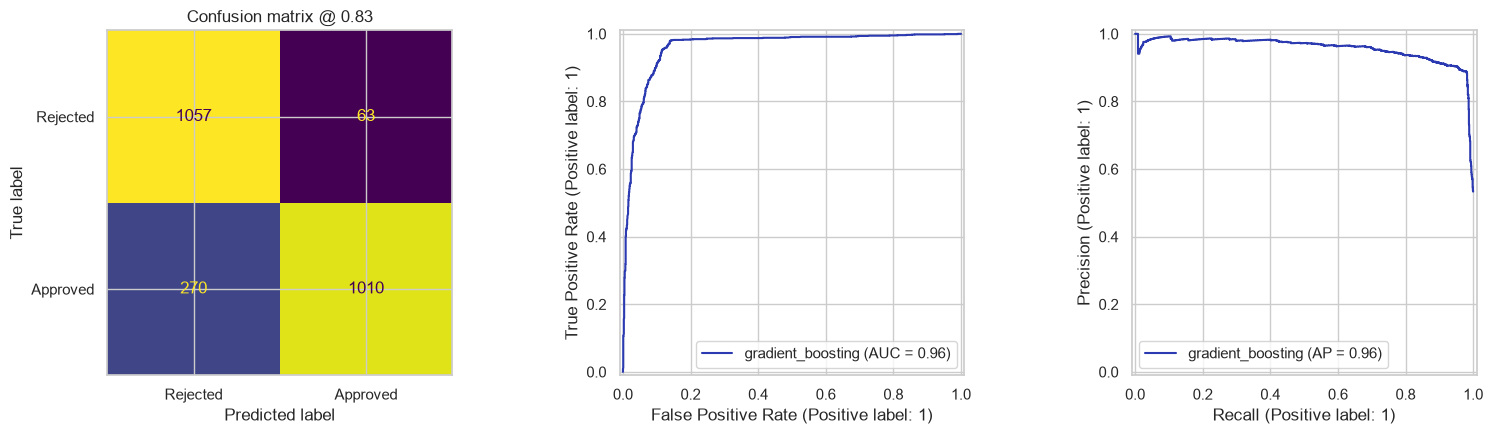

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= card["decision_threshold"]).astype(int),
    display_labels=["Rejected", "Approved"], ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix @ {card['decision_threshold']}")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name=chosen)
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[2], name=chosen)
plt.tight_layout(); plt.show()

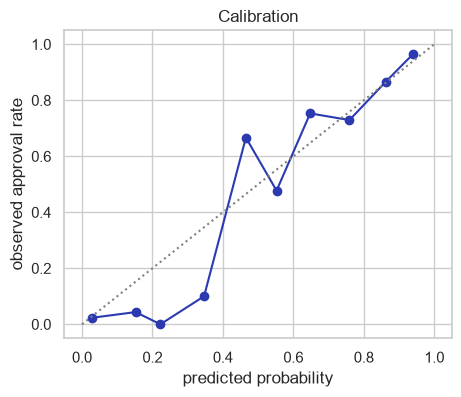

In [8]:
from sklearn.calibration import calibration_curve
frac, mean = calibration_curve(y_test, proba, n_bins=10)
plt.figure(figsize=(5, 4)); plt.plot(mean, frac, marker="o"); plt.plot([0, 1], [0, 1], ":", color="grey")
plt.xlabel("predicted probability"); plt.ylabel("observed approval rate"); plt.title("Calibration"); plt.show()

## 4. What drives the model

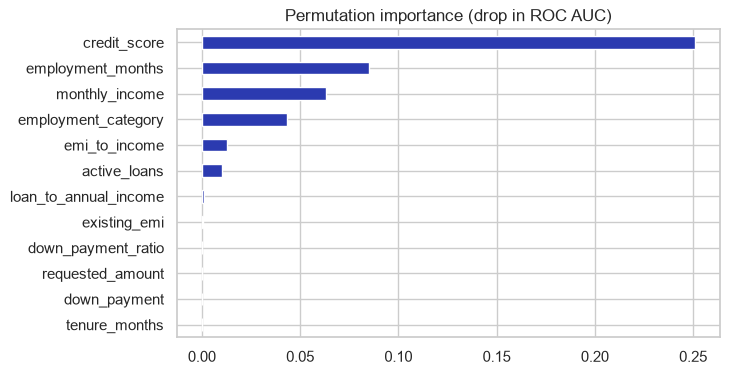

In [9]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(saved._pipeline, x_test[FEATURES], y_test, scoring="roc_auc", n_repeats=5,
                             random_state=P.SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 4), title="Permutation importance (drop in ROC AUC)"); plt.show()

## 5. Error analysis

In [10]:
errors = x_test.assign(actual=y_test, proba=proba, pred=(proba >= card["decision_threshold"]).astype(int))
false_approvals = errors[(errors.pred == 1) & (errors.actual == 0)]
false_rejections = errors[(errors.pred == 0) & (errors.actual == 1)]
summary = pd.DataFrame({"false approvals": false_approvals[FEATURES[:6]].median(numeric_only=True),
                        "false rejections": false_rejections[FEATURES[:6]].median(numeric_only=True),
                        "all test": x_test[FEATURES[:6]].median(numeric_only=True)}).round(1)
print(len(false_approvals), "false approvals,", len(false_rejections), "false rejections")
summary

63 false approvals, 270 false rejections


,false approvals,false rejections,all test
monthly_income,57750.0,55200.0,54450.0
credit_score,694.0,689.0,702.0
employment_months,48.0,37.0,38.0
existing_emi,4700.0,11600.0,4200.0
active_loans,1.0,2.0,1.0
requested_amount,1160000.0,915000.0,890000.0


Most remaining false approvals are borderline profiles near the policy limits or carry the
injected label noise (manual exceptions recorded as rejections). False rejections cluster at moderate
scores with higher existing EMIs; those applicants get a cited reason and can request manual review
(policy clause 5.1).

## 6. Interaction with the written policy

In [11]:
from app.domain.applicant import ApplicantInput
from app.domain.eligibility import evaluate
from app.domain.policy import PolicyDocument
policy = PolicyDocument.model_validate_json((ROOT / "data/documents/policy/NW-AUTO-STD-2026.1.json").read_text())
sample = df.sample(400, random_state=P.SEED)
rows = []
for r in sample.itertuples():
    if pd.isna(r.monthly_income) or pd.isna(r.credit_score) or pd.isna(r.employment_months):
        continue
    a = ApplicantInput(income_amount=str(r.monthly_income), income_frequency="monthly", credit_score=int(r.credit_score),
        score_provider="CIBIL", employment_category=r.employment_category if r.employment_category in
        ("salaried", "self_employed", "unemployed", "retired", "student") else "other",
        employment_months=int(r.employment_months), existing_monthly_obligations=str(r.existing_emi if r.existing_emi == r.existing_emi else 0),
        active_loans=int(r.active_loans) if r.active_loans == r.active_loans else 0,
        requested_principal=str(max(100000, r.requested_amount)), requested_tenure_months=int(r.tenure_months),
        down_payment_available=str(r.down_payment if r.down_payment == r.down_payment else 0), currency="INR", jurisdiction="IN", region="IN-MH")
    score = saved.score(a)
    rules_only = evaluate(a, policy.model_copy(update={"rules": policy.rules.model_copy(update={"credit_risk": None})}))
    combined = evaluate(a, policy, score.probability)
    rows.append({"rules": rules_only.outcome, "final": combined.outcome, "label": r.loan_status})
gate = pd.DataFrame(rows)
pd.crosstab(gate.rules, gate.final, margins=True)

final,APPROVED,REJECTED,All
rules,,,
APPROVED,162,55,217
REJECTED,0,147,147
All,162,202,364


The rules alone decide most rejections, each with a cited clause. The model only acts on
applications that already satisfy every written rule, and it declines the riskier part of that group.
That is where a learned model adds value without contradicting the policy.

## 7. Sanctioned amount: why rules, not a model

The sanctioned amount is **calculated** by the deterministic engine: income x maximum debt-service ratio,
minus existing EMIs, converted to principal at the policy rate and tenure, then capped by the product maximum,
the requested amount and, per vehicle, the loan-to-value limit. A regression model could approximate this,
but it could not *guarantee* the brief's hard requirement that the amount never exceeds what the policy
allows, and its output could not be traced to clauses. The rules give an exact, explainable, replayable
number.

The model, threshold, metrics and data hash are recorded in `models/model_card.json`, and every decision
snapshot stores the model version and artifact hash for audit and replay.